# Optimized ESC-50 evaluation

This self-contained notebook loads the best saved checkpoint and evaluates it on the held-out fold 5. It produces the final accuracy and visual error analysis.

In [1]:
"""Optimized ESC-50 training pipeline with reproducible visual artifacts.

This file is independent from the baseline and improved notebooks.  It trains on
folds 1-3, validates on fold 4, and never reads fold 5.
"""

from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import pytorch_lightning as pl
import torch
import torchaudio
from pytorch_lightning.callbacks import EarlyStopping, ModelCheckpoint
from torch import nn
from torch.nn import functional as F
from torchmetrics.classification import MulticlassAccuracy, MulticlassF1Score


ROOT = Path.cwd()
DATA_PATH = ROOT / "ESC-50-master" / "ESC-50-master"
OUTPUT_DIR = ROOT / "outputs" / "optimized"
SAMPLE_RATE = 16_000
N_CLASSES = 50


class ESC50Dataset(torch.utils.data.Dataset):
    """Loads ESC-50 clips as normalized log-Mel spectrograms."""

    def __init__(self, folds, augment=False):
        self.csv = pd.read_csv(DATA_PATH / "meta" / "esc50.csv")
        self.csv = self.csv[self.csv["fold"].isin(folds)].reset_index(drop=True)
        self.augment = augment
        self.resample = torchaudio.transforms.Resample(44_100, SAMPLE_RATE)
        self.melspec = torchaudio.transforms.MelSpectrogram(
            sample_rate=SAMPLE_RATE,
            n_fft=1024,
            hop_length=256,
            n_mels=96,
        )
        self.to_db = torchaudio.transforms.AmplitudeToDB(top_db=80)
        self.time_mask = torchaudio.transforms.TimeMasking(time_mask_param=32)
        self.freq_mask = torchaudio.transforms.FrequencyMasking(freq_mask_param=10)

    def __len__(self):
        return len(self.csv)

    def __getitem__(self, index):
        row = self.csv.iloc[index]
        waveform, _ = torchaudio.load(DATA_PATH / "audio" / row["filename"])
        waveform = self.resample(waveform)

        # Random gain changes make training less dependent on recording volume.
        if self.augment:
            gain_db = torch.empty(1).uniform_(-6.0, 6.0).item()
            waveform = waveform * (10 ** (gain_db / 20))

        features = self.to_db(self.melspec(waveform))
        features = (features - features.mean()) / (features.std() + 1e-5)

        # SpecAugment applies only to training examples, never validation/test data.
        if self.augment:
            features = self.time_mask(features)
            features = self.freq_mask(features)

        return features, int(row["target"])


class ResidualBlock(nn.Module):
    def __init__(self, in_channels, out_channels, dropout=0.15):
        super().__init__()
        self.conv1 = nn.Conv2d(in_channels, out_channels, 3, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_channels)
        self.conv2 = nn.Conv2d(out_channels, out_channels, 3, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_channels)
        self.dropout = nn.Dropout2d(dropout)
        self.skip = (
            nn.Identity()
            if in_channels == out_channels
            else nn.Sequential(
                nn.Conv2d(in_channels, out_channels, 1, bias=False),
                nn.BatchNorm2d(out_channels),
            )
        )

    def forward(self, x):
        residual = self.skip(x)
        x = F.gelu(self.bn1(self.conv1(x)))
        x = self.dropout(x)
        x = self.bn2(self.conv2(x))
        return F.gelu(x + residual)


class OptimizedAudioNet(pl.LightningModule):
    def __init__(self):
        super().__init__()
        self.save_hyperparameters()
        self.stem = nn.Sequential(
            nn.Conv2d(1, 32, 5, padding=2, bias=False),
            nn.BatchNorm2d(32),
            nn.GELU(),
        )
        self.features = nn.Sequential(
            ResidualBlock(32, 32),
            nn.MaxPool2d(2),
            ResidualBlock(32, 64),
            nn.MaxPool2d(2),
            ResidualBlock(64, 128),
            nn.MaxPool2d(2),
            ResidualBlock(128, 128),
        )
        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Dropout(0.30),
            nn.Linear(128, N_CLASSES),
        )
        self.train_accuracy = MulticlassAccuracy(num_classes=N_CLASSES)
        self.val_accuracy = MulticlassAccuracy(num_classes=N_CLASSES)
        self.val_f1 = MulticlassF1Score(num_classes=N_CLASSES, average="macro")

    def forward(self, x):
        return self.classifier(self.features(self.stem(x)))

    def training_step(self, batch, batch_idx):
        x, y = batch
        logits = self(x)
        loss = F.cross_entropy(logits, y, label_smoothing=0.08)
        accuracy = self.train_accuracy(logits, y)
        self.log_dict(
            {"train_loss": loss, "train_acc": accuracy},
            on_step=False,
            on_epoch=True,
            prog_bar=True,
        )
        return loss

    def validation_step(self, batch, batch_idx):
        x, y = batch
        logits = self(x)
        loss = F.cross_entropy(logits, y)
        accuracy = self.val_accuracy(logits, y)
        f1 = self.val_f1(logits, y)
        self.log_dict(
            {"val_loss": loss, "val_acc": accuracy, "val_macro_f1": f1},
            on_step=False,
            on_epoch=True,
            prog_bar=True,
        )

    def configure_optimizers(self):
        optimizer = torch.optim.AdamW(self.parameters(), lr=1e-3, weight_decay=2e-4)
        scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
            optimizer, mode="min", factor=0.5, patience=5
        )
        return {
            "optimizer": optimizer,
            "lr_scheduler": {"scheduler": scheduler, "monitor": "val_loss"},
        }


class HistoryCallback(pl.Callback):
    """Writes a metrics CSV and a training/validation curve after fitting."""

    def __init__(self, output_dir):
        self.output_dir = output_dir
        self.rows = []

    def on_validation_epoch_end(self, trainer, pl_module):
        metrics = trainer.callback_metrics

        def value(name):
            item = metrics.get(name)
            return float(item.detach().cpu()) if item is not None else None

        self.rows.append(
            {
                "epoch": trainer.current_epoch + 1,
                "train_loss": value("train_loss"),
                "train_acc": value("train_acc"),
                "val_loss": value("val_loss"),
                "val_acc": value("val_acc"),
                "val_macro_f1": value("val_macro_f1"),
            }
        )

    def on_fit_end(self, trainer, pl_module):
        history = pd.DataFrame(self.rows).dropna(how="all")
        history.to_csv(self.output_dir / "training_history.csv", index=False)
        fig, axes = plt.subplots(1, 2, figsize=(12, 4))
        axes[0].plot(history["epoch"], history["train_loss"], label="Training loss")
        axes[0].plot(history["epoch"], history["val_loss"], label="Validation loss")
        axes[0].set(title="Loss by epoch", xlabel="Epoch", ylabel="Cross-entropy loss")
        axes[0].legend()
        axes[0].grid(alpha=0.25)
        axes[1].plot(history["epoch"], history["train_acc"], label="Training accuracy")
        axes[1].plot(history["epoch"], history["val_acc"], label="Validation accuracy")
        axes[1].plot(history["epoch"], history["val_macro_f1"], label="Validation macro F1")
        axes[1].set(title="Validation quality by epoch", xlabel="Epoch", ylabel="Score", ylim=(0, 1))
        axes[1].legend()
        axes[1].grid(alpha=0.25)
        fig.tight_layout()
        fig.savefig(self.output_dir / "training_curves.png", dpi=180)
        plt.close(fig)


def main():
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    pl.seed_everything(42, workers=True)
    torch.set_float32_matmul_precision("high")

    train_data = ESC50Dataset(folds=[1, 2, 3], augment=True)
    val_data = ESC50Dataset(folds=[4], augment=False)
    train_loader = torch.utils.data.DataLoader(train_data, batch_size=32, shuffle=True)
    val_loader = torch.utils.data.DataLoader(val_data, batch_size=32)

    # Visual sanity check: one normalized log-Mel spectrogram used by the model.
    sample, label = val_data[0]
    fig, ax = plt.subplots(figsize=(10, 4))
    image = ax.imshow(sample[0], aspect="auto", origin="lower", cmap="magma")
    fig.colorbar(image, ax=ax, label="Normalized log-Mel value")
    ax.set(title=f"Validation spectrogram (class {label})", xlabel="Time frames", ylabel="Mel band")
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / "sample_spectrogram.png", dpi=180)
    plt.close(fig)

    checkpoint = ModelCheckpoint(
        dirpath=OUTPUT_DIR,
        filename="optimized-best",
        monitor="val_acc",
        mode="max",
        save_top_k=1,
    )
    early_stop = EarlyStopping(monitor="val_acc", mode="max", patience=15)
    history = HistoryCallback(OUTPUT_DIR)
    model = OptimizedAudioNet()
    trainer = pl.Trainer(
        accelerator="auto",
        devices=1,
        max_epochs=80,
        callbacks=[checkpoint, early_stop, history],
        log_every_n_steps=10,
    )
    trainer.fit(model, train_loader, val_loader)
    print(f"Best checkpoint: {checkpoint.best_model_path}")
    print(f"Best validation accuracy: {checkpoint.best_model_score:.3f}")



In [2]:
def evaluate_model():
    checkpoint = OUTPUT_DIR / "optimized-best.ckpt"
    if not checkpoint.exists():
        raise FileNotFoundError("Run train-optimized.ipynb first to create the checkpoint.")

    model = OptimizedAudioNet.load_from_checkpoint(checkpoint).eval()
    device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
    model = model.to(device)
    test_data = ESC50Dataset(folds=[5], augment=False)
    test_loader = torch.utils.data.DataLoader(test_data, batch_size=32)

    predictions, targets = [], []
    with torch.no_grad():
        for features, labels in test_loader:
            logits = model(features.to(device))
            predictions.append(logits.argmax(dim=1).cpu())
            targets.append(labels)
    predictions = torch.cat(predictions).numpy()
    targets = torch.cat(targets).numpy()

    label_names = (
        pd.read_csv(DATA_PATH / "meta" / "esc50.csv")[["target", "category"]]
        .drop_duplicates()
        .set_index("target")["category"]
    )
    meta = test_data.csv.copy()
    results = pd.DataFrame(
        {
            "filename": meta["filename"],
            "target": targets,
            "prediction": predictions,
        }
    )
    results["category"] = results["target"].map(label_names)
    results["predicted_category"] = results["prediction"].map(label_names)
    results["correct"] = results["target"] == results["prediction"]
    results.to_csv(OUTPUT_DIR / "optimized_test_predictions.csv", index=False)

    accuracy = results["correct"].mean()
    confusion = torch.bincount(
        torch.tensor(targets * N_CLASSES + predictions), minlength=N_CLASSES**2
    ).reshape(N_CLASSES, N_CLASSES).numpy()
    normalized = confusion / confusion.sum(axis=1, keepdims=True).clip(min=1)

    fig, ax = plt.subplots(figsize=(12, 10))
    image = ax.imshow(normalized, cmap="Blues", vmin=0, vmax=1)
    fig.colorbar(image, ax=ax, label="Fraction of true class")
    ax.set(
        title="Normalized confusion matrix — optimized model",
        xlabel="Predicted class index",
        ylabel="True class index",
    )
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / "confusion_matrix.png", dpi=180)
    plt.close(fig)

    class_accuracy = pd.DataFrame(
        {
            "target": range(N_CLASSES),
            "category": [label_names[index] for index in range(N_CLASSES)],
            "accuracy": normalized.diagonal(),
            "samples": confusion.sum(axis=1),
        }
    ).sort_values("accuracy")
    class_accuracy.to_csv(OUTPUT_DIR / "per_class_accuracy.csv", index=False)

    display = pd.concat([class_accuracy.head(10), class_accuracy.tail(10)]).sort_values("accuracy")
    fig, ax = plt.subplots(figsize=(10, 8))
    colors = ["#c44e52" if value < 0.5 else "#55a868" for value in display["accuracy"]]
    ax.barh(display["category"], display["accuracy"], color=colors)
    ax.axvline(accuracy, color="#4c72b0", linestyle="--", label=f"Overall: {accuracy:.1%}")
    ax.set(title="10 hardest and 10 easiest ESC-50 classes", xlabel="Test accuracy", xlim=(0, 1))
    ax.legend()
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / "per_class_accuracy.png", dpi=180)
    plt.close(fig)

    example_indices = list(results.index[~results["correct"]][:6]) + list(results.index[results["correct"]][:6])
    fig, axes = plt.subplots(3, 4, figsize=(14, 8))
    for ax, index in zip(axes.flat, example_indices):
        features, _ = test_data[index]
        row = results.iloc[index]
        ax.imshow(features[0], aspect="auto", origin="lower", cmap="magma")
        color = "#c44e52" if not row["correct"] else "#55a868"
        ax.set_title(f"True: {row['category']}\nPred: {row['predicted_category']}", color=color, fontsize=8)
        ax.axis("off")
    fig.suptitle("Example test spectrograms (red = incorrect, green = correct)", y=0.98)
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / "prediction_examples.png", dpi=180)
    plt.close(fig)

    print(f"Optimized test accuracy: {accuracy:.3f} ({results['correct'].sum()}/{len(results)})")
    print(f"Saved reports in: {OUTPUT_DIR}")





## Run final evaluation

This takes a few seconds and refreshes the result files.

In [3]:
evaluate_model()


Optimized test accuracy: 0.720 (288/400)
Saved reports in: /Users/atharva/Desktop/Pettichat Internship/esc50-my-first-run/outputs/optimized


## Results and visual analysis

Final test accuracy: 72.0% (288/400 clips)


,target,category,accuracy,samples
0,40,helicopter,0.125,8
1,23,breathing,0.125,8
2,48,fireworks,0.250,8
3,34,can_opening,0.375,8
4,29,drinking_sipping,0.375,8
5,22,clapping,0.375,8
6,38,clock_tick,0.375,8
7,47,airplane,0.375,8
8,6,hen,0.375,8
9,25,footsteps,0.500,8


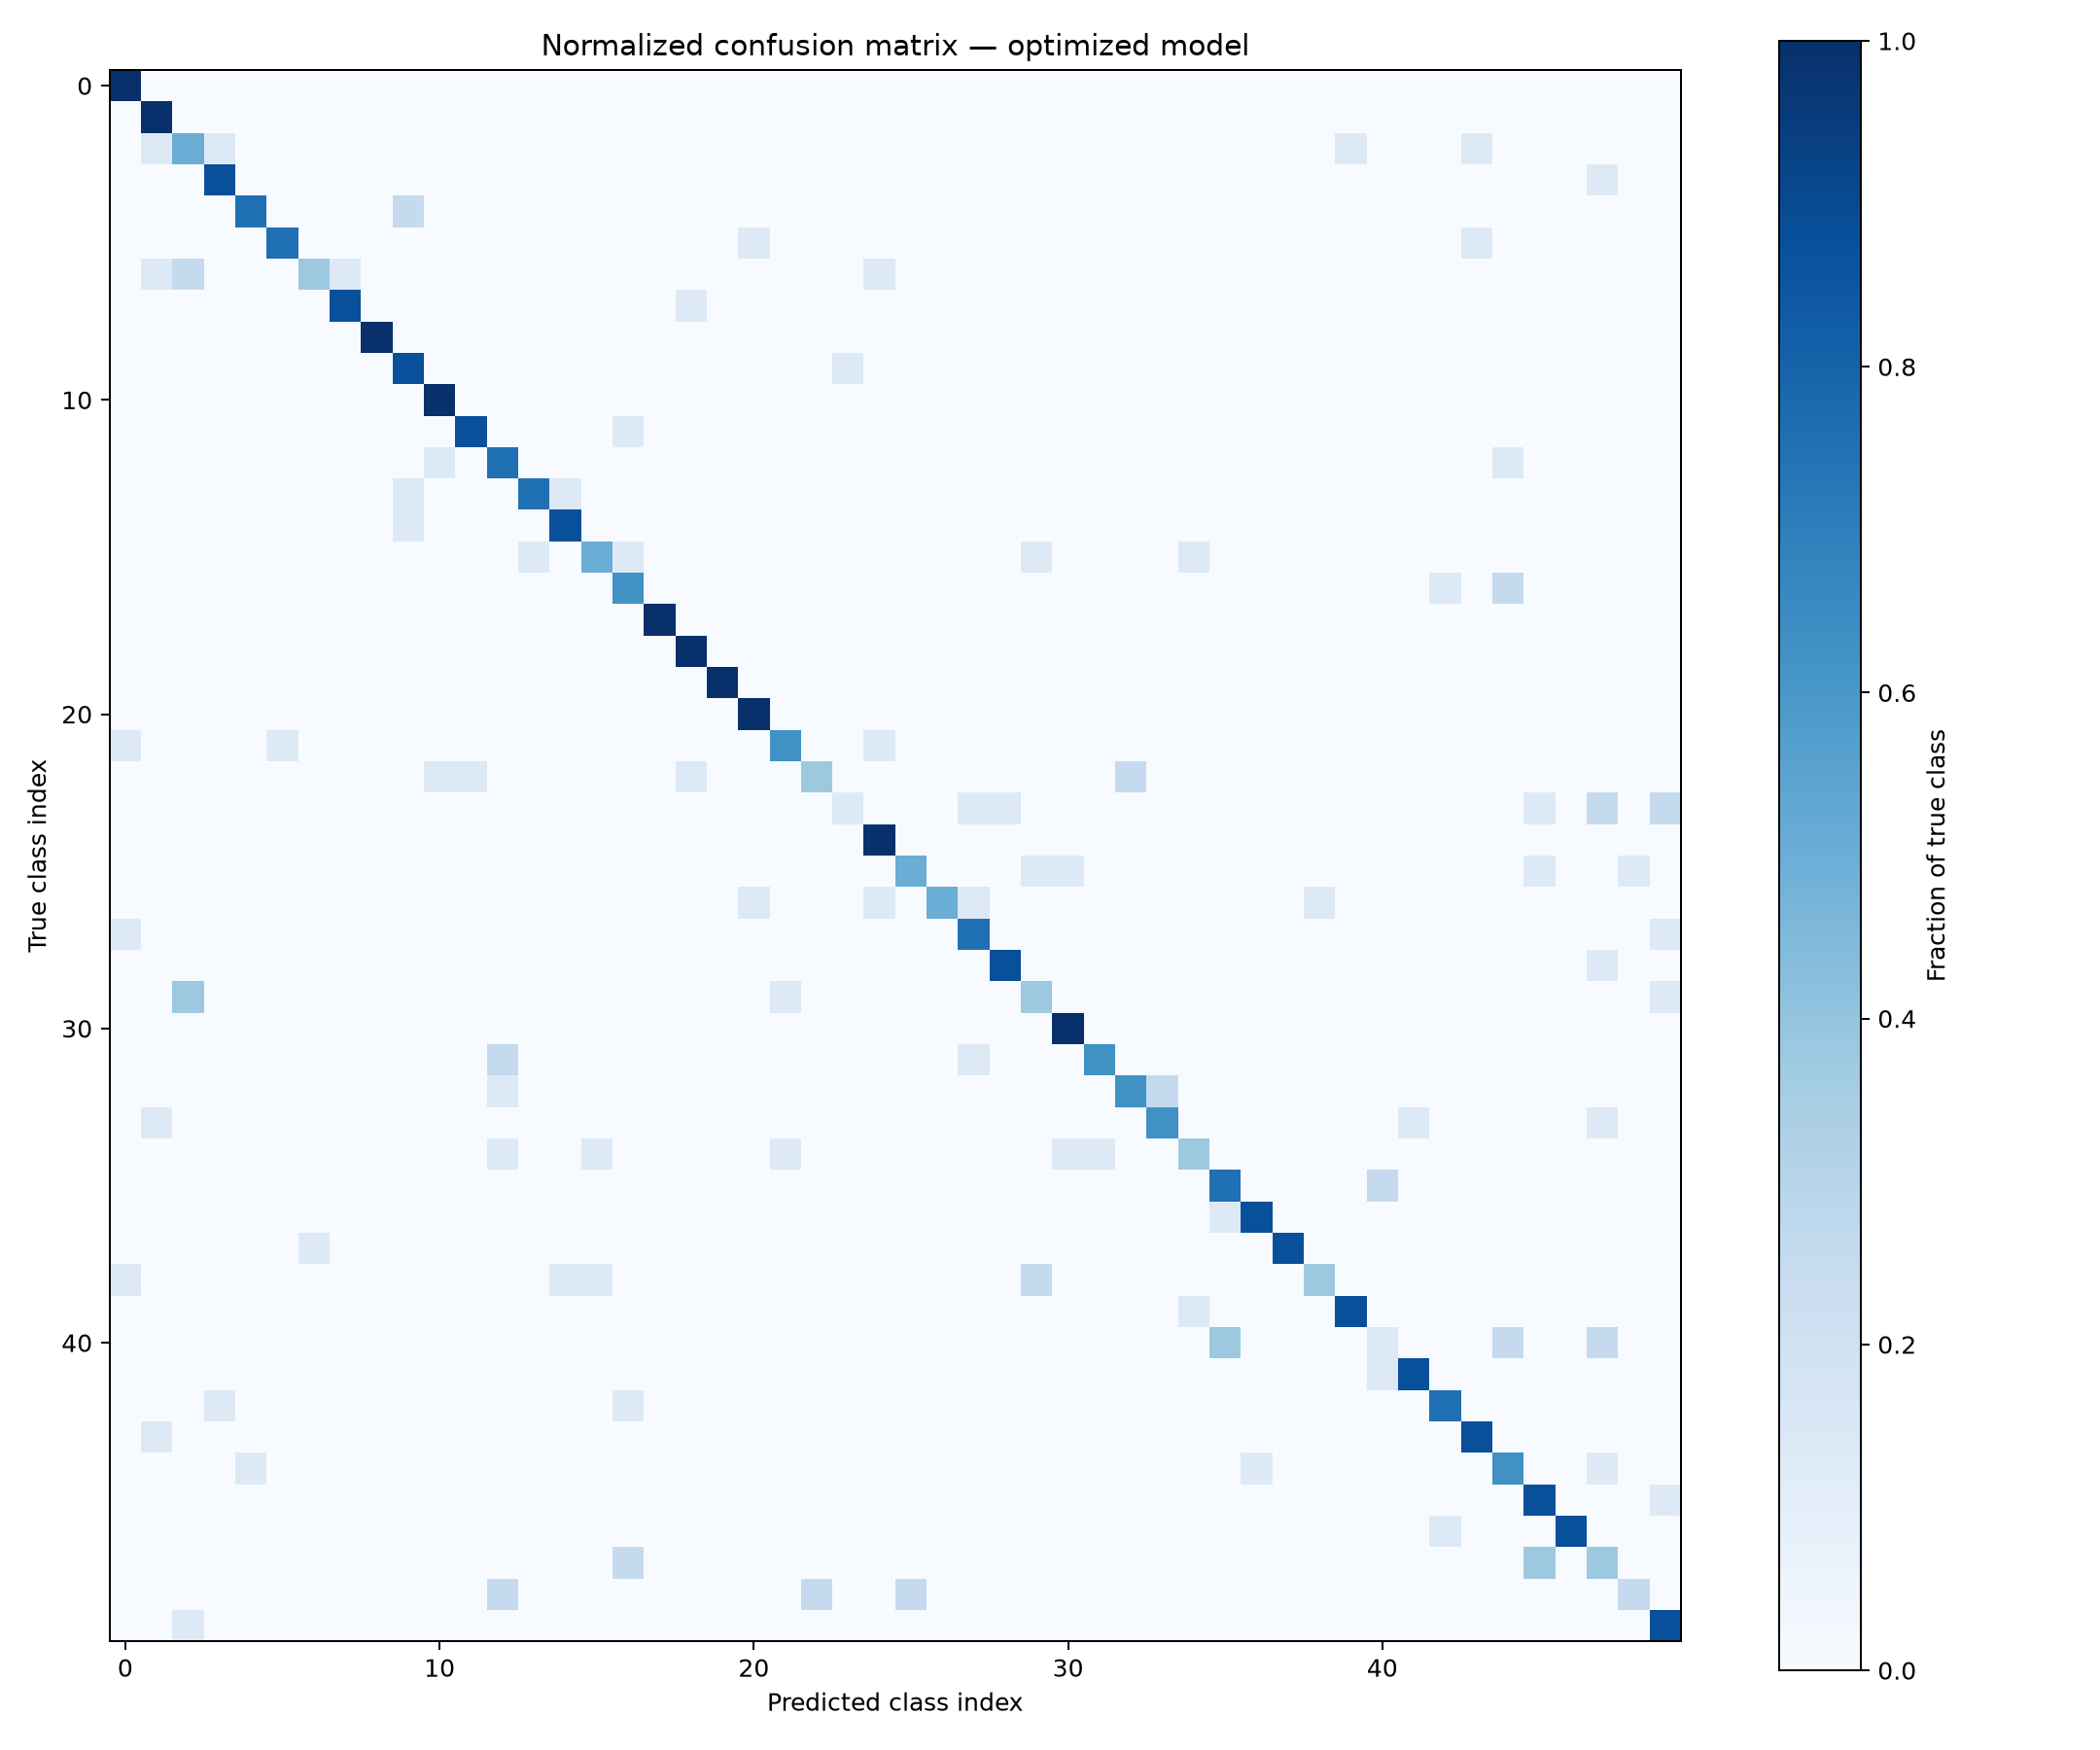

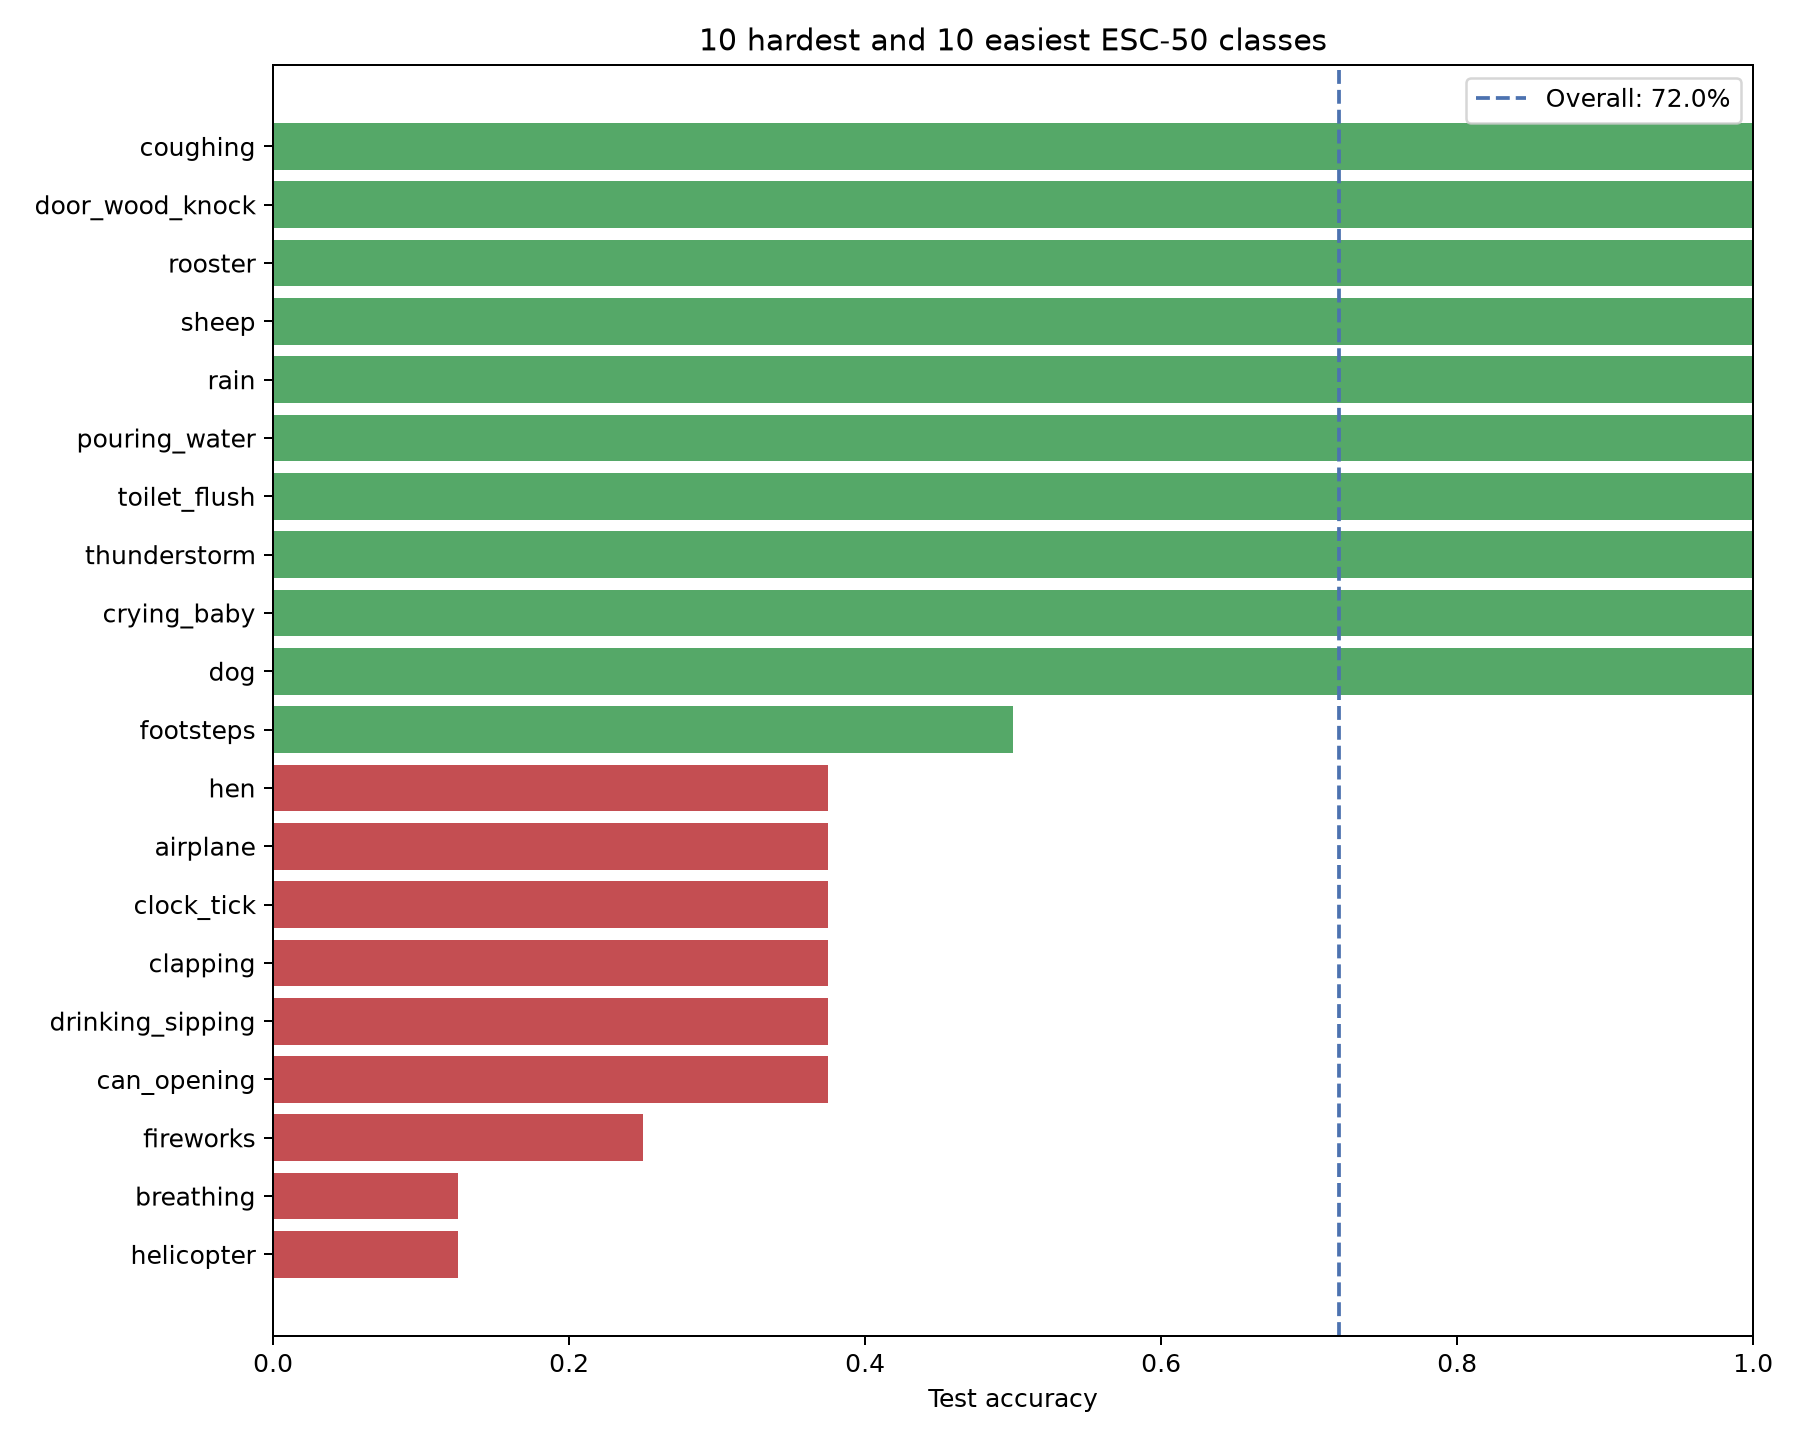

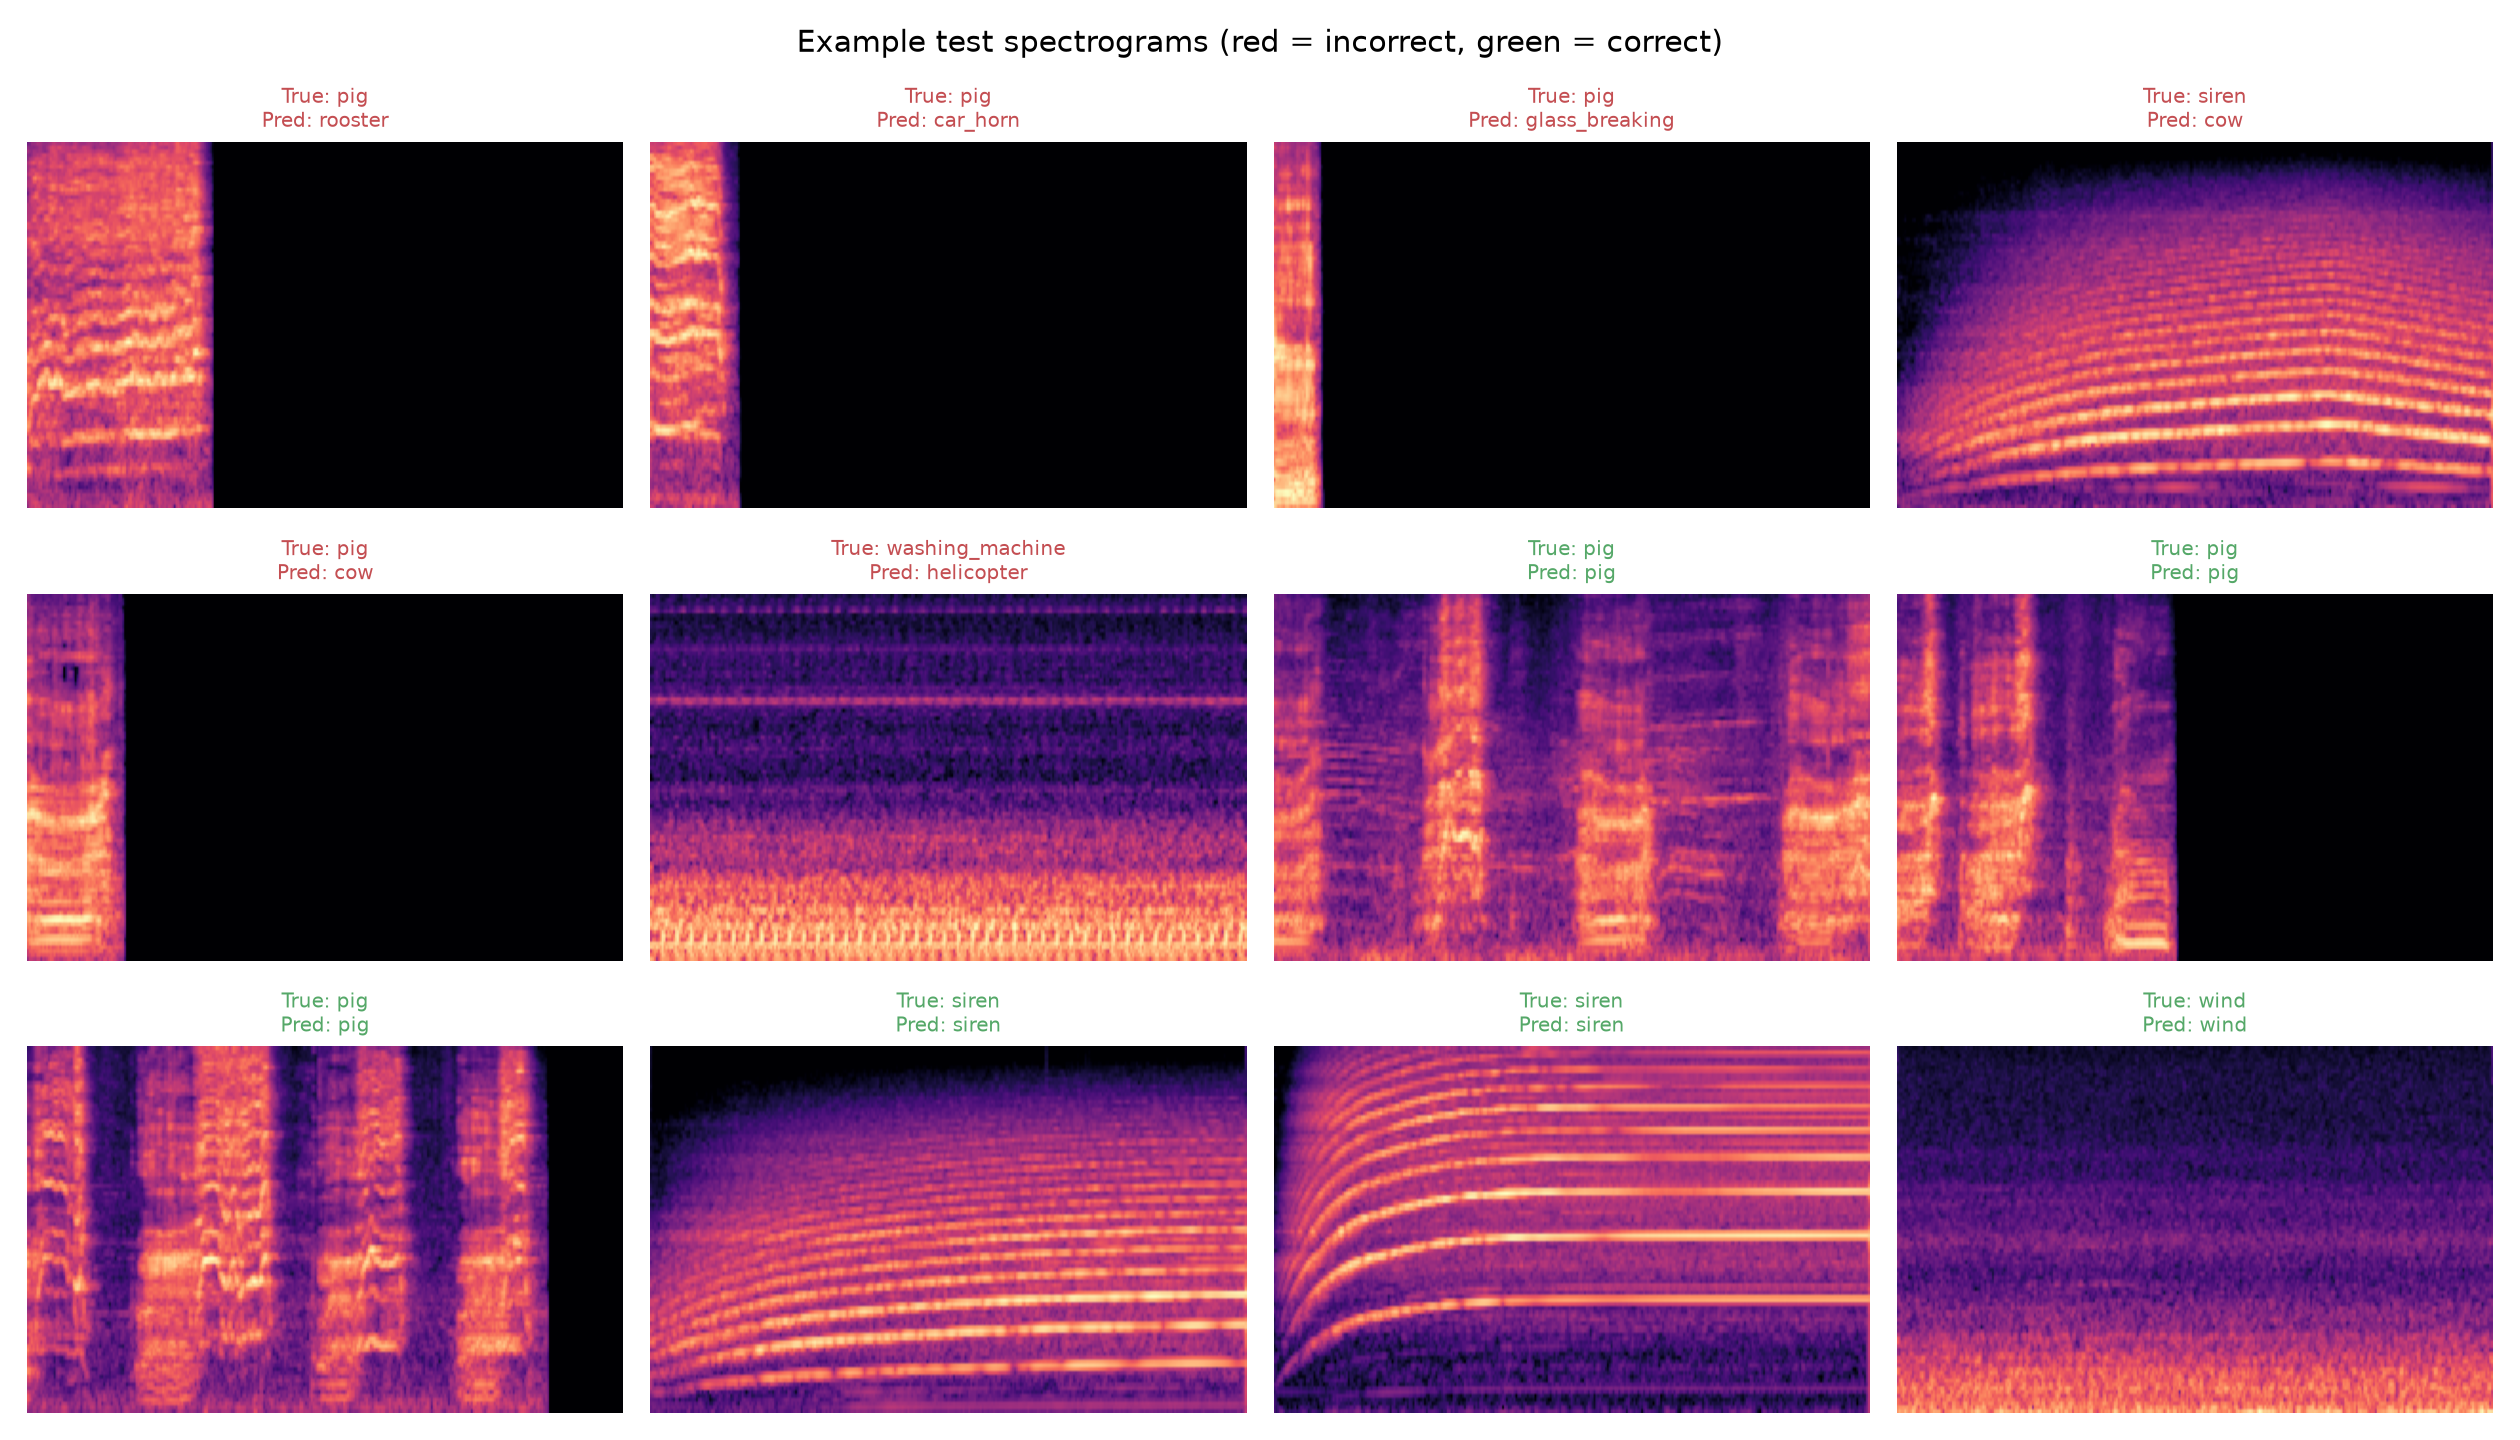

In [4]:
from IPython.display import Image, display
predictions = pd.read_csv(OUTPUT_DIR / 'optimized_test_predictions.csv')
print(f"Final test accuracy: {predictions['correct'].mean():.1%} ({predictions['correct'].sum()}/{len(predictions)} clips)")
display(pd.read_csv(OUTPUT_DIR / 'per_class_accuracy.csv'))
display(Image(filename=str(OUTPUT_DIR / 'confusion_matrix.png')))
display(Image(filename=str(OUTPUT_DIR / 'per_class_accuracy.png')))
display(Image(filename=str(OUTPUT_DIR / 'prediction_examples.png')))
